> **Telecommunication Lab Exam | Experiment 12**  
> Based on *Telecommunication-Lab.pdf*, PDF pages 35–36.  
> **Use:** Read the theory → run the two code cells → identify the output → practice the viva answers.  
> **Software:** Python 3, Jupyter/Colab, `numpy`, `matplotlib`. **Only Exp 1 optionally needs `scipy`.**



# Experiment 12: Convolutional Encoding, Viterbi Decoding & SNR

## 1. Aim
To implement a **(2,1,2) Convolutional Encoder**, introduce transmission errors, and recover the original message using the **Viterbi decoding algorithm**. Also, to study the effect of **AWGN noise and SNR (Eb/N0)** on digital transmission.

---

## 2. Theory

### A. Convolutional Encoding
Convolutional coding is a Forward Error Correction (FEC) technique that introduces redundant bits to improve communication reliability.

Unlike block coding, convolutional encoding depends on:
- The current input bit
- Previous input bits stored in shift registers

Our encoder uses:
- **Input bits (k):** 1
- **Output bits (n):** 2
- **Memory elements (m):** 2
- **Code rate:** 1/2
- **Constraint length (K):** 3

### Important Formulas

**Code Rate:**

$$
R = \frac{k}{n} = \frac{1}{2}
$$

**Constraint Length:**

$$
K = m + 1 = 2 + 1 = 3
$$

**Generator Equations:**

$$
c_1 = u \oplus d_1 \oplus d_2
$$

$$
c_2 = u \oplus d_2
$$

Where:
- $u$ = Current input bit
- $d_1$ = First shift-register state
- $d_2$ = Second shift-register state
- $\oplus$ = XOR (modulo-2 addition)

Generator connections:

$$
g_1 = 111,\qquad g_2 = 101
$$

---

## 3. Encoding Example

**Original Message:**

`1011`

Two terminating zeros are added to reset the shift registers.

**Encoder Input:**

`101100`

| Input | d1 | d2 | c1 | c2 | Output |
|---|---|---|---|---|---|
| 1 | 0 | 0 | 1 | 1 | 11 |
| 0 | 1 | 0 | 1 | 0 | 10 |
| 1 | 0 | 1 | 0 | 0 | 00 |
| 1 | 1 | 0 | 0 | 1 | 01 |
| 0 | 1 | 1 | 0 | 1 | 01 |
| 0 | 0 | 1 | 1 | 1 | 11 |

*The register states shown are before processing each input bit.*

**Encoded Output:**

`11 10 00 01 01 11`

**Final Encoded Stream:**

`111000010111`

---

## 4. Error Insertion

During transmission, noise may change some bits from `0` to `1` or from `1` to `0`.

We can manually introduce an error using:

```python
received = encoded.copy()
received[3] ^= 1
```

Here, `^= 1` flips the fourth transmitted bit.

**Original Encoded Stream:**

`111000010111`

**Received Stream with One Error:**

`111100010111`

The receiver must identify the most likely transmitted sequence.

---

## 5. Viterbi Decoding

The **Viterbi algorithm** is a maximum-likelihood sequence decoding algorithm commonly used for convolutional codes.

It uses a **trellis diagram** to represent possible encoder states and transitions.

### Working Principle

1. Start from the initial zero state.
2. Consider possible input bits `0` and `1`.
3. Calculate the expected encoded output for each transition.
4. Compare expected bits with received bits.
5. Calculate the branch metric using Hamming distance.
6. Keep the minimum-cost path for each state.
7. Trace back the best path to recover the input message.

### Hamming Distance

Hamming distance counts the number of differing bits between two binary sequences.

$$
d_H(x,y) = \sum_{i=1}^{n}(x_i \oplus y_i)
$$

Example:

`Expected = 11`

`Received = 10`

$$
d_H(11,10)=1
$$

### Path Metric

$$
PM_{\text{new}} = PM_{\text{old}} + d_H
$$

The decoder selects the path having the minimum accumulated metric.

For our zero-terminated encoder, the final encoder state is known to be `00`.

**Recovered Message:**

`1011`

The manually introduced error is corrected successfully.

---

## 6. SNR and AWGN Noise

### What is SNR?

Signal-to-Noise Ratio (SNR) compares signal strength with noise strength.

$$
SNR = \frac{P_{\text{signal}}}{P_{\text{noise}}}
$$

In decibels:

$$
SNR_{dB}=10\log_{10}(SNR)
$$

Our Python simulation specifically uses **Eb/N0**, the energy-per-information-bit to noise-power-spectral-density ratio.

### What is AWGN?

AWGN stands for **Additive White Gaussian Noise**.

It is commonly used to simulate random noise in communication channels.

**Received signal:**

$$
y = s + n
$$

Where:
- $s$ = Transmitted BPSK signal
- $n$ = Gaussian noise
- $y$ = Received noisy signal

### BPSK Mapping

$$
0 \rightarrow +1
$$

$$
1 \rightarrow -1
$$

### Convert Eb/N0 from dB to Linear

$$
\gamma_b=10^{(E_b/N_0)_{dB}/10}
$$

### Noise Standard Deviation

For normalized BPSK with code rate $R$:

$$
\sigma=\sqrt{\frac{1}{2R\gamma_b}}
$$

In this experiment:

$$
R=\frac12
$$

The noisy received samples are generated using:

```python
noisy = symbols + rng.normal(0, sigma, len(symbols))
```

### Hard-Decision Detection

```python
rx_noisy = (noisy < 0).astype(int).tolist()
```

Decision rule:
- Positive sample → `0`
- Negative sample → `1`

The detected bits are passed to the Viterbi decoder.

### Effect of Eb/N0

| Eb/N0 | Expected Behavior |
|---|---|
| Low (0 dB) | More noise and likely more errors |
| Medium (2 dB) | Moderate noise |
| Higher (5 dB) | Fewer errors on average |
| High (8 dB) | More reliable detection |

A larger Eb/N0 generally reduces the Bit Error Rate.

However, a short message may produce different results due to randomness.

---

## 7. Bit Error Rate (BER)

BER measures the fraction of incorrectly received bits.

$$
BER=\frac{\text{Number of Bit Errors}}{\text{Total Number of Bits}}
$$

For example, if 1 out of 12 transmitted coded bits is incorrect:

$$
BER=\frac{1}{12}\approx0.0833
$$

$$
BER\approx8.33\%
$$

The Viterbi decoder may correct the error, giving zero message-bit errors after decoding.

**Important:** A proper BER performance curve requires a large number of transmitted bits and repeated simulations at different Eb/N0 values.

## 3. Runnable Python implementation

**Run the next cell** to compute the signal and print essential results. The following cell draws the output waveforms. Use **Run All** to execute both in order.

Original Message: [1, 0, 1, 1]
Encoded Bits: [1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1]
With One Error: [1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1]
Viterbi Decoded: [1, 0, 1, 1]
SNR (Eb/N0): 2 dB
Noisy Received: [1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1]
Decoded After Noise: [1, 0, 1, 1]


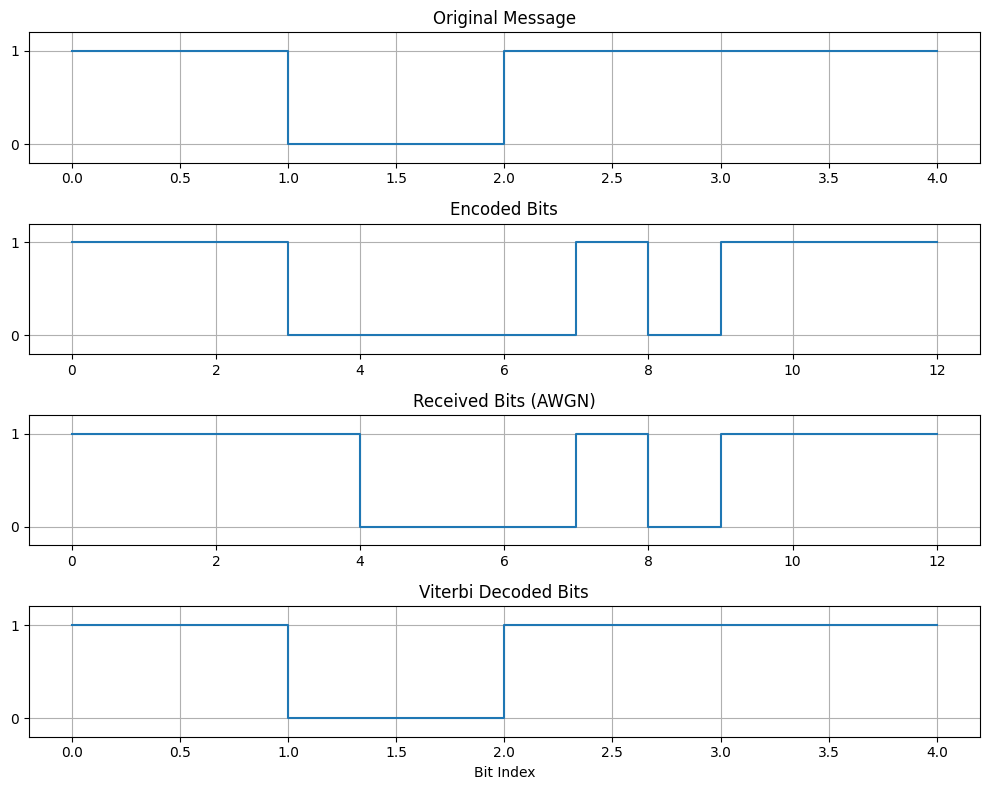

In [1]:

"""Experiment 12: Convolutional Coding, Viterbi Decoding and SNR."""
import numpy as np
import matplotlib.pyplot as plt

# 1. Convolutional Encoding (2,1,2)
message = [1, 0, 1, 1]
input_bits = message + [0, 0]  # Two terminating zeros
d1 = d2 = 0
encoded = []

for bit in input_bits:
    c1 = bit ^ d1 ^ d2       # Generator g1 = 111
    c2 = bit ^ d2            # Generator g2 = 101
    encoded += [c1, c2]
    d2, d1 = d1, bit         # Update shift registers

# 2. Viterbi Decoder (Hard Decision)
def viterbi(rx):
    paths = {(0, 0): (0, [])}

    for i in range(0, len(rx), 2):
        new = {}
        for (d1, d2), (cost, path) in paths.items():
            for bit in [0, 1]:
                expected = [bit ^ d1 ^ d2, bit ^ d2]
                errors = sum(a != b for a, b in zip(expected, rx[i:i+2]))
                state = (bit, d1)
                candidate = (cost + errors, path + [bit])

                if state not in new or candidate[0] < new[state][0]:
                    new[state] = candidate
        paths = new

    return paths[(0, 0)][1][:-2]  # Remove two tail bits

# 3. Add One Manual Bit Error
received = encoded.copy()
received[3] ^= 1            # Flip fourth encoded bit
corrected = viterbi(received)

# 4. Add Noise using SNR (Eb/N0)
EbN0_dB = 2                 # Change to 0, 2, 5, 8 dB
R = 1/2                     # Code rate
rng = np.random.default_rng(1)

symbols = 1 - 2*np.array(encoded)  # BPSK: 0 -> +1, 1 -> -1
snr = 10**(EbN0_dB/10)
sigma = np.sqrt(1/(2*R*snr))

noisy = symbols + rng.normal(0, sigma, len(symbols))
rx_noisy = (noisy < 0).astype(int).tolist()
decoded_noisy = viterbi(rx_noisy)

# 5. Display Results
print("Original Message:", message)
print("Encoded Bits:", encoded)
print("With One Error:", received)
print("Viterbi Decoded:", corrected)
print("SNR (Eb/N0):", EbN0_dB, "dB")
print("Noisy Received:", rx_noisy)
print("Decoded After Noise:", decoded_noisy)

# 6. Plot Waveforms
fig, ax = plt.subplots(4, 1, figsize=(10, 8))

signals = [message, encoded, rx_noisy, decoded_noisy]
titles = ["Original Message", "Encoded Bits",
          "Received Bits (AWGN)", "Viterbi Decoded Bits"]

for a, signal, title in zip(ax, signals, titles):
    a.step(range(len(signal)+1), signal+[signal[-1]], where='post')
    a.set_title(title)
    a.set_yticks([0, 1])
    a.set_ylim(-0.2, 1.2)
    a.grid(True)

ax[-1].set_xlabel("Bit Index")
plt.tight_layout()
plt.show()

## 8. Expected Output

**Original Message:** `1011`

**Encoded Stream:** `111000010111`

**Received with One Error:** `111100010111`

**Viterbi Decoded:** `1011`

**Example Eb/N0:** `2 dB`

**Recovered Message after AWGN:** `1011` (for the fixed random seed used in the program)

### Expected Graphs

1. **Original Message:** Four binary message bits.
2. **Encoded Stream:** Twelve coded bits containing redundancy.
3. **Noisy Received Bits:** Bits detected after AWGN is added.
4. **Viterbi Decoded Bits:** Recovered original four-bit message.

---

## 9. Applications

- Satellite communication
- Deep-space communication
- Wireless and mobile communication
- Digital broadcasting
- Error-correction systems

### Advantages

1. Improves communication reliability.
2. Enables correction of many transmission errors.
3. Works effectively in noisy channels.
4. Viterbi decoding provides an efficient decoding method for modest constraint lengths.

### Disadvantages

1. Adds redundant bits and increases transmitted data.
2. Requires additional decoding complexity.
3. Decoder processing introduces delay.
4. Cannot guarantee correction of every error pattern.

---

## 10. Important Viva Questions

**Q1. What is convolutional coding?**

A Forward Error Correction technique that generates redundant output bits using current and previous input bits.

**Q2. What is the code rate?**

The ratio of input bits to output bits. Here, it is 1/2.

**Q3. What is constraint length?**

The number of input-bit positions influencing the encoder output. Here, K = 3.

**Q4. Why are shift registers used?**

To store previous input bits and provide memory to the encoder.

**Q5. Why are two zeros added?**

To terminate the encoder and return its memory to the zero state.

**Q6. What is Viterbi decoding?**

A sequence-decoding algorithm that selects the most likely transmitted path through a trellis.

**Q7. What is Hamming distance?**

The number of differing bit positions between two binary sequences.

**Q8. What is AWGN?**

Additive White Gaussian Noise, used to model random communication-channel noise.

**Q9. What happens when SNR increases?**

Noise becomes weaker relative to the signal, so BER generally decreases.

**Q10. What is the difference between encoding and decoding?**

Encoding adds redundancy, while decoding uses that redundancy to recover the most likely original message.

**Q11. Can Viterbi decoding correct all errors?**

No. It can correct many error patterns but may fail when channel errors are too severe.

**Q12. What is the main advantage of convolutional coding?**

Improved reliability through error correction.

---

## 11. Result and Conclusion

A (2,1,2) convolutional encoder was implemented successfully using XOR gates and two shift registers.

The input message `1011` was encoded into `111000010111`.

A transmission error was introduced manually, and the original message was recovered using hard-decision Viterbi decoding.

AWGN noise was also added to simulate a noisy communication channel. The experiment demonstrates how convolutional coding and Viterbi decoding improve communication reliability.

**Final Conclusion:** Convolutional coding adds redundancy to digital data, and Viterbi decoding can use that redundancy to correct transmission errors.
